In [25]:

# Step 1: Load occupancy data

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error

file = "/content/5occupancySensor_MayToDec2024_9MRows.zip"
cols = ["deviceid", "floorspaceid", "collecteddate", "headcount"]

sample = pd.read_csv(file, compression="zip",
                     usecols=cols, nrows=100000)

zone_id, device_id = (
    sample.groupby(["floorspaceid", "deviceid"])
    .size().idxmax()
)

parts = []
for chunk in pd.read_csv(file, compression="zip",
                         usecols=cols, chunksize=200000):
    rows = chunk[(chunk["deviceid"] == device_id) &
                 (chunk["floorspaceid"] == zone_id)]
    if not rows.empty:
        parts.append(rows[["collecteddate", "headcount"]])

raw = pd.concat(parts, ignore_index=True)

print("Selected zone:", zone_id)
print("Selected device:", device_id)
print("Total records:", len(raw))
display(raw.head())


Selected zone: 0f3f37f8-0335-41e0-ae87-a1d677dfc7d7
Selected device: 56923747-b390-4f2a-8930-808429132266
Total records: 2169461


,collecteddate,headcount
0,2023-11-24 00:37:32+11,1
1,2023-11-24 00:37:52+11,0
2,2023-11-24 00:38:32+11,0
3,2023-11-24 00:41:32+11,1
4,2023-11-24 00:42:12+11,0


In [26]:

%%writefile project_utils.py
import pandas as pd

def build_features(series):
    """Create inputs and targets for 5-minute occupancy prediction.

    Args:
        series: Observed headcount at 5-minute intervals.

    Returns:
        DataFrame containing three inputs and the next headcount.
        Rows with missing observations are excluded.
    """
    return pd.DataFrame({
        "now": series,
        "lag5": series.shift(1),
        "lag10": series.shift(2),
        "next5": series.shift(-1)
    }).dropna()


Overwriting project_utils.py


In [27]:

# Step 2: Clean and prepare data

raw["time"] = pd.to_datetime(
    raw["collecteddate"], utc=True, errors="coerce"
)
raw["headcount"] = pd.to_numeric(raw["headcount"], errors="coerce")
raw = raw.dropna(subset=["time", "headcount"])
raw = raw[raw["headcount"] >= 0]

series = (
    raw.sort_values("time")
    .set_index("time")["headcount"]
    .resample("5min").last()
)


from project_utils import build_features
data = build_features(series)


print("Valid samples:", len(data))
print("Zero targets (%):", round((data["next5"] == 0).mean()*100, 2))
print("Missing values:", data.isna().sum().sum())
display(data.head())



Valid samples: 96728
Zero targets (%): 28.73
Missing values: 0


,now,lag5,lag10,next5
time,,,,
2023-11-23 21:00:00+00:00,0.0,0.0,0.0,0.0
2023-11-23 21:25:00+00:00,1.0,0.0,0.0,1.0
2023-11-23 21:30:00+00:00,1.0,1.0,0.0,0.0
2023-11-23 21:55:00+00:00,1.0,1.0,0.0,0.0
2023-11-23 22:50:00+00:00,1.0,0.0,1.0,1.0


In [28]:

# Step 3: Train and compare models

features = ["now", "lag5", "lag10"]

a, b = int(len(data)*0.6), int(len(data)*0.8)
train, val, test = data.iloc[:a], data.iloc[a:b], data.iloc[b:]

models = {
    "Linear Regression": LinearRegression(),
    "Decision Tree": DecisionTreeRegressor(
        max_depth=4, random_state=42
    )
}

predictions = {"Baseline": val["now"].to_numpy()}

for name, model in models.items():
    model.fit(train[features], train["next5"])
    predictions[name] = np.maximum(
        model.predict(val[features]), 0
    )

results = []
for name, pred in predictions.items():
    results.append({
        "Model": name,
        "MAE": mean_absolute_error(val["next5"], pred),
        "RMSE": np.sqrt(mean_squared_error(val["next5"], pred))
    })

display(pd.DataFrame(results).round(4))
print("Train:", len(train), "Validation:", len(val),
      "Test:", len(test))


,Model,MAE,RMSE
0,Baseline,0.7893,1.2843
1,Linear Regression,0.7340,1.0929
2,Decision Tree,0.7637,1.1577


Train: 58036 Validation: 19346 Test: 19346


In [29]:

# Step 4: Optimise Decision Tree

depths = [2, 3, 4, 6, 8]
errors = []

for d in depths:
    model = DecisionTreeRegressor(
        max_depth=d, min_samples_leaf=20, random_state=42
    )
    model.fit(train[features], train["next5"])
    pred = np.maximum(model.predict(val[features]), 0)
    errors.append(mean_absolute_error(val["next5"], pred))

best_depth = depths[np.argmin(errors)]

print("Best depth:", best_depth)
display(pd.DataFrame({
    "Depth": depths,
    "Validation MAE": errors
}).round(4))

# Retrain final models using training + validation data
train_val = pd.concat([train, val])

linear_final = LinearRegression().fit(
    train_val[features], train_val["next5"]
)

tree_final = DecisionTreeRegressor(
    max_depth=best_depth, min_samples_leaf=20, random_state=42
).fit(train_val[features], train_val["next5"])


Best depth: 8


,Depth,Validation MAE
0,2,0.7824
1,3,0.7604
2,4,0.7621
3,6,0.7488
4,8,0.7434


,Model,MAE,RMSE
0,Baseline,0.6826,1.1273
1,Linear Regression,0.6381,0.9382
2,Decision Tree,0.6495,0.9299


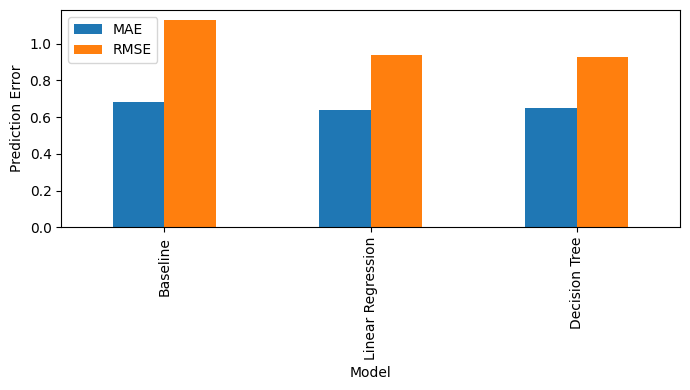

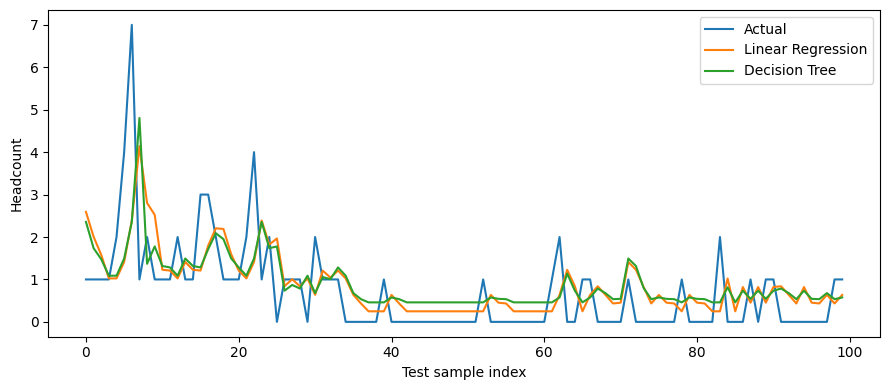

In [30]:

# Step 5: Final testing and results

y = test["next5"]

predictions = {
    "Baseline": test["now"].to_numpy(),
    "Linear Regression": np.maximum(
        linear_final.predict(test[features]), 0),
    "Decision Tree": np.maximum(
        tree_final.predict(test[features]), 0)
}

results = pd.DataFrame([
    {
        "Model": name,
        "MAE": mean_absolute_error(y, pred),
        "RMSE": np.sqrt(mean_squared_error(y, pred))
    }
    for name, pred in predictions.items()
])

display(results.round(4))
results.to_csv("results.csv", index=False)

# Figure 1: Model comparison
results.set_index("Model")[["MAE", "RMSE"]].plot(
    kind="bar", figsize=(7, 4)
)
plt.ylabel("Prediction Error")
plt.tight_layout()
plt.savefig("model_comparison.png", dpi=150)
plt.show()

# Figure 2: Actual vs predicted
plt.figure(figsize=(9, 4))
plt.plot(y.to_numpy()[:100], label="Actual")
plt.plot(predictions["Linear Regression"][:100],
         label="Linear Regression")
plt.plot(predictions["Decision Tree"][:100],
         label="Decision Tree")
plt.xlabel("Test sample index")
plt.ylabel("Headcount")
plt.legend()
plt.tight_layout()
plt.savefig("predictions.png", dpi=150)
plt.show()


In [31]:

# Step 6: Verify data and predictions

assert len(data) > 0
assert not data.isna().any().any()
assert (data >= 0).all().all()

assert train.index.max() < val.index.min()
assert val.index.max() < test.index.min()

for pred in predictions.values():
    assert len(pred) == len(test)
    assert np.isfinite(pred).all()
    assert (pred >= 0).all()

print("All verification checks passed!")


All verification checks passed!


In [32]:

%%writefile test_project_utils.py
import pandas as pd
from project_utils import build_features

def test_features():
    s = pd.Series([0, 1, 2, 3, 4, 5])
    result = build_features(s)
    assert len(result) == 3
    assert result.loc[2, "next5"] == 3
    assert result.loc[2, "lag10"] == 0

def test_missing_data():
    s = pd.Series([0, 1, 2, 3, None, 5, 6])
    result = build_features(s)
    assert len(result) == 1
    assert not result.isna().any().any()

def test_short_data():
    s = pd.Series([1, 2, 3])
    assert build_features(s).empty


Overwriting test_project_utils.py


In [33]:

# Step 8: Run unit tests and save report

!python -m pytest -v test_project_utils.py | tee test_report.txt


============================= test session starts ==============================
platform linux -- Python 3.13.16, pytest-8.4.2, pluggy-1.7.0 -- /usr/bin/python3
cachedir: .pytest_cache
rootdir: /content
plugins: platformdirs-4.13.5, anyio-4.15.1, typeguard-4.6.0, langsmith-0.14.11
collecting ... collected 3 items

test_project_utils.py::test_features PASSED                              [ 33%]
test_project_utils.py::test_missing_data PASSED                          [ 66%]
test_project_utils.py::test_short_data PASSED                            [100%]

============================== 3 passed in 0.51s ===============================


In [34]:


# Step 9: Generate HTML documentation

%pip -q install pdoc

!python -m pdoc /content/project_utils.py -o /content/docs

from pathlib import Path
assert Path("/content/docs/project_utils.html").exists()
print("HTML created successfully!")


HTML created successfully!


In [35]:

%%writefile README.md
# MMA3001 - Building Occupancy Prediction

## Project Overview
This project predicts building occupancy five minutes ahead
using historical occupancy sensor data.

## Dataset
Monash Smart Infrastructure Occupancy Dataset.
Input: timestamp, device ID, zone ID and headcount.
The original dataset is not included in this repository.

## Methods
- Baseline: current headcount
- Linear Regression
- Decision Tree Regression

Data is split chronologically into:
60% training, 20% validation and 20% testing.

Decision Tree depth is selected using validation MAE.
Models are evaluated using MAE and RMSE.

## Running the Project
1. Open MMA3001_Project.ipynb in Google Colab.
2. Upload the course-provided occupancy ZIP file.
3. Run all notebook cells in order.

## Project Files
- MMA3001_Project.ipynb: Main analysis
- project_utils.py: Feature preparation
- test_project_utils.py: Unit tests
- test_report.txt: Test results
- docs/: HTML documentation
- results.csv: Model comparison
- *.png: Result figures

## Limitations
Predictions are evaluated only where consecutive
five-minute intervals have observed headcounts.
Results may not generalise to other zones or devices.


Overwriting README.md


In [36]:

# Step 11: Save Python dependencies

!python -m pip freeze | grep -E '^(pandas|numpy|matplotlib|scikit-learn|pytest|pdoc)==' > requirements.txt

print("Requirements created!")
print(open("requirements.txt").read())


Requirements created!
matplotlib==3.10.0
numpy==2.1.3
pandas==2.2.3
pdoc==16.0.0
pytest==8.4.2
scikit-learn==1.6.1



In [37]:

%%writefile LICENSE
MIT License

Copyright (c) 2026 KangChen

Permission is hereby granted, free of charge, to any person obtaining a copy
of this software and associated documentation files (the "Software"), to deal
in the Software without restriction, including without limitation the rights
to use, copy, modify, merge, publish, distribute, sublicense, and/or sell
copies of the Software, and to permit persons to whom the Software is
furnished to do so, subject to the following conditions:

The above copyright notice and this permission notice shall be included in all
copies or substantial portions of the Software.

THE SOFTWARE IS PROVIDED "AS IS", WITHOUT WARRANTY OF ANY KIND, EXPRESS OR
IMPLIED, INCLUDING BUT NOT LIMITED TO THE WARRANTIES OF MERCHANTABILITY,
FITNESS FOR A PARTICULAR PURPOSE AND NONINFRINGEMENT. IN NO EVENT SHALL THE
AUTHORS OR COPYRIGHT HOLDERS BE LIABLE FOR ANY CLAIM, DAMAGES OR OTHER
LIABILITY, WHETHER IN AN ACTION OF CONTRACT, TORT OR OTHERWISE, ARISING FROM,
OUT OF OR IN CONNECTION WITH THE SOFTWARE OR THE USE OR OTHER DEALINGS IN THE
SOFTWARE.


Overwriting LICENSE
